# 04 — Comparaison des modèles de régression

**Objectif :** comparer 8 modèles (GP, GAM, Random Forest, CatBoost, XGBoost, SVR, Elastic Net, BART) pour prédire Q10 dans des régions sans mesure, et voir s'ils battent la valeur fixe Q10 = 2.0 et la régression de Hacopian.

**Protocole** (décisions validées, cf. `02_selection_variables.ipynb`) :
- données : `data/dataset_v4.csv` (131 sites) ; cible log(Q10), erreurs toujours mesurées sur l'échelle de Q10 ;
- validation croisée **spatiale** : zones de 10° × 10°, 5 plis répétés 20 fois, découpages identiques pour tous les modèles (`src/protocole.py`) ;
- deux variantes par modèle : **V1** avec les 12 candidats, **V2** avec une sélection LASSO (pénalité minimale) refaite dans chaque pli d'entraînement ;
- hyperparamètres réglés par une validation croisée spatiale interne ;
- règle de choix : **le modèle le plus simple dont l'erreur est à moins d'une erreur standard de celle du meilleur**, avec en second critère le comportement en extrapolation.

**Partie A — Références** : ce qu'il faut battre. **Partie B — Les 8 modèles** : performance en validation croisée spatiale. **Partie C — Comportement en extrapolation.** **Partie D — Le coefficient de détermination R².**

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat**.

In [1]:
# Imports : données, graphiques, régression linéaire et fonctions communes du protocole (dossier src/)
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from src.protocole import decoupages_spatiaux, evaluer, resumer, comparer, Q10_REFERENCE

In [2]:
# Chargement de la table de modélisation (cf. 02_selection_variables, partie B, étape 4)
v4 = pd.read_csv("../data/dataset_v4.csv")

In [3]:
# Découpages de la validation croisée spatiale, identiques pour tous les modèles
decoupages = decoupages_spatiaux(v4.bloc)

## Partie A — Références

### Étape 1 — Les quatre références

**Objectif :** mesurer, avec exactement le même protocole que les futurs modèles, l'erreur des références à battre.

**Raisonnement :**
- **Q10 = 2.0** : la valeur fixe à battre (cf. `INSTRUCTIONS.md` ; constante `Q10_REFERENCE` de `src/protocole.py`), qui ne s'entraîne pas.
- **Moyenne** : la moyenne des Q10 des sites d'entraînement de chaque pli.
- **Hacopian réentraîné** : sa forme de modèle, une régression linéaire Q10 ~ MAT + MAP + pH sur Q10 directement, réentraînée sur chaque pli.
- **Hacopian publié** : les coefficients de son script R (Q10 = 0.1093 − 0.0315·MAT + 0.0002·MAP + 0.4112·pH), appliqués tels quels, sans entraînement. C'est l'équation qui a servi à sa carte mondiale.

In [4]:
# Prédictions de l'équation publiée par Hacopian, pour tous les sites
hacopian_publie = 0.1093 - 0.0315 * v4.MAT_public + 0.0002 * v4.MAP_public + 0.4112 * v4.pH_public

In [5]:
# Variables du modèle de Hacopian (MAT, MAP brute en mm/an, pH)
H = v4[["MAT_public", "MAP_public", "pH_public"]]

In [6]:
# Nom de la référence « valeur fixe » dans les tableaux
ref = f"Q10 = {Q10_REFERENCE}"  # par exemple « Q10 = 2.0 »


In [7]:
# Évaluation des quatre références sur les mêmes découpages spatiaux
references = {
    ref: evaluer(lambda tr, te: np.full(len(te), Q10_REFERENCE), decoupages, v4.Q10),
    "moyenne": evaluer(lambda tr, te: np.full(len(te), v4.Q10.iloc[tr].mean()), decoupages, v4.Q10),
    "Hacopian réentraîné": evaluer(lambda tr, te: LinearRegression().fit(H.iloc[tr], v4.Q10.iloc[tr]).predict(H.iloc[te]), decoupages, v4.Q10),
    "Hacopian publié": evaluer(lambda tr, te: hacopian_publie.iloc[te], decoupages, v4.Q10),
}

In [8]:
# Tableau récapitulatif : RMSE, MAE, R² et gain par rapport à la valeur fixe de référence
rmse_ref = references[ref][0].rmse.mean()
pd.DataFrame({k: resumer(s, o, v4.Q10, rmse_ref) for k, (s, o) in references.items()}).T.round(3)

,RMSE,MAE,R²,gain vs référence (%)
Q10 = 2.0,1.083,0.791,-0.264,0.000
moyenne,0.980,0.748,-0.033,9.536
Hacopian réentraîné,0.963,0.717,-0.000,11.113
Hacopian publié,0.994,0.757,-0.057,8.251


**Constat :**
- **Hacopian réentraîné** fait le mieux : 0.963, soit 11.1 % d'erreur en moins que Q10 = 2.0 et 1.7 % de moins que la moyenne.
- **La moyenne** bat déjà 2.0 de 9.5 %, simplement parce que le Q10 moyen de nos sites (2.51) est bien supérieur à 2.0. **L'essentiel du gain sur 2.0 vient donc du niveau moyen de Q10**, pas des variables. Réserve : nos sites ne représentent pas la planète, et rien ne garantit que le Q10 moyen mondial soit proche de 2.51.
- **Hacopian publié** fait 8.3 % de mieux que 2.0, mais moins bien que la moyenne.
- **Les R² sont tous inférieurs ou égaux à 0** : en prédisant des régions nouvelles, aucune de ces références n'explique la variabilité de Q10.

### Étape 2 — L'équation publiée de Hacopian généralise-t-elle à de nouveaux sites ?

**Objectif :** vérifier si l'équation publiée tient hors de ses propres données.

**Raisonnement :** 70 de nos 131 sites (`source = paper`) viennent de l'étude de Hacopian : son équation a été ajustée dessus. Les 61 autres sont nouveaux pour elle. On compare son erreur à celle de Q10 = 2.0 sur chacun des deux groupes.

In [9]:
# RMSE de l'équation publiée et de la valeur fixe, sur les sites de Hacopian et sur les autres sites
groupe = np.where(v4.source == "paper", "sites de Hacopian", "autres sites")
erreurs = pd.DataFrame({"Hacopian publié": (v4.Q10 - hacopian_publie) ** 2, ref: (v4.Q10 - Q10_REFERENCE) ** 2})
erreurs.groupby(groupe).mean().pow(0.5).assign(sites=pd.Series(groupe).value_counts()).round(3)

,Hacopian publié,Q10 = 2.0,sites
autres sites,1.124,1.106,61
sites de Hacopian,0.914,1.118,70


**Constat :** sur ses propres sites, l'équation publiée bat nettement 2.0 (0.914 contre 1.118). Sur les 61 sites qu'elle n'a pas vus, elle fait **moins bien que 2.0** (1.124 contre 1.106). **Elle ne généralise donc pas** : elle est trop ajustée à ses données d'origine. C'est exactement le piège que notre validation croisée spatiale doit éviter. Réserve : les deux groupes de sites ne couvrent pas les mêmes régions.

### Étape 3 — Comment décider qu'un modèle fait vraiment mieux qu'un autre

**Objectif :** préciser la règle de choix validée (« le plus simple à moins d'une erreur standard du meilleur »).

**Raisonnement :** l'erreur varie beaucoup d'un pli à l'autre, selon les régions retirées. Calculée sur les plis d'un seul modèle, l'erreur standard dépasse tous les écarts entre modèles : la règle déclarerait alors tous les modèles équivalents, et choisirait la constante. On compare donc les modèles **sur les mêmes plis** (écart apparié). L'erreur standard de cet écart est corrigée selon Nadeau et Bengio (2003), car en validation croisée répétée les jeux d'entraînement se recouvrent et les plis ne sont pas indépendants. Ce calcul est fait par `comparer` dans `src/protocole.py`.

In [10]:
# Écarts appariés de RMSE : Hacopian réentraîné et moyenne, comparés à la valeur fixe et entre eux
pd.DataFrame({
    f"Hacopian réentraîné − {ref}": comparer(references["Hacopian réentraîné"][0], references[ref][0]),
    f"moyenne − {ref}": comparer(references["moyenne"][0], references[ref][0]),
    "Hacopian réentraîné − moyenne": comparer(references["Hacopian réentraîné"][0], references["moyenne"][0]),
}).T.round(3)

,écart,erreur standard,plis où a fait mieux (%)
Hacopian réentraîné − Q10 = 2.0,-0.120,0.046,92.0
moyenne − Q10 = 2.0,-0.103,0.049,89.0
Hacopian réentraîné − moyenne,-0.017,0.028,65.0


**Constat :**
- Hacopian réentraîné bat Q10 = 2.0 de 0.120 ± 0.046, et la moyenne le bat de 0.103 ± 0.049 : ces écarts **dépassent deux erreurs standard** (mieux dans 92 % et 89 % des plis). Battre 2.0 est donc net… mais à la portée d'une simple constante.
- Hacopian réentraîné contre la moyenne (−0.017 ± 0.028) reste **sous une erreur standard** : selon notre règle, ces deux modèles ne se distinguent pas.
- Les erreurs standard des écarts sont de l'ordre de **0.03** : pour être jugé clairement meilleur qu'un autre, un modèle devra le battre d'au moins ≈ 0.03 de RMSE.

## Résumé de la partie A

| Référence | RMSE (validation croisée spatiale) | Gain vs 2.0 |
|---|---|---|
| Q10 = 2.0 | 1.083 | — |
| moyenne | 0.980 | 9.5 % |
| Hacopian publié | 0.994 | 8.3 % |
| **Hacopian réentraîné** | **0.963** | **11.1 %** |

Pour mémoire, les modèles linéaires sur nos 12 candidats font ≈ 0.953 (Ridge, LASSO ; cf. `02_selection_variables.ipynb`, partie C).

**La barre à franchir pour les 8 modèles** : faire nettement mieux que Hacopian réentraîné (0.963), c'est-à-dire d'au moins une erreur standard d'écart (≈ 0.03).

## Partie B — Les 8 modèles

### Étape 1 — Les modèles et leurs réglages

**Objectif :** évaluer les 8 modèles, chacun en deux variantes (V1 : 12 candidats ; V2 : sélection LASSO refaite dans chaque pli), soit 16 configurations, sur les mêmes 100 plis spatiaux que les références.

**Raisonnement :** les modèles sont définis une seule fois dans `src/modeles.py`. Tous apprennent log(Q10), et leurs prédictions sont ramenées à Q10. Les grilles d'hyperparamètres sont volontairement petites (131 sites, 100 plis) ; elles sont réglées par une validation croisée spatiale **interne** à chaque pli d'entraînement.

| Modèle | Implémentation | Réglage interne | Comportement attendu hors du domaine des données (vérifié en partie C) |
|---|---|---|---|
| Elastic Net | scikit-learn | `alpha`, `l1_ratio` (30 combinaisons) | prolonge une droite en log, donc une exponentielle sur Q10 |
| GAM | pygam : une spline pénalisée par variable continue, effet linéaire pour la végétation | `lam` (5 valeurs) | prolonge les courbes, parfois de façon instable |
| SVR (noyau RBF) | scikit-learn | `C`, `gamma`, `epsilon` (36) | revient vers une constante |
| GP | scikit-learn : noyau RBF avec une échelle par variable (ARD) + bruit | vraisemblance marginale (pas de grille) | revient vers la moyenne |
| Random Forest | scikit-learn, 200 arbres | `max_features`, `min_samples_leaf` (4) | constante |
| XGBoost | xgboost, 300 arbres | `max_depth`, `reg_lambda` (4) | constante |
| CatBoost | catboost, 300 arbres ; typologie en variable catégorielle native (V1) | `depth`, `l2_leaf_reg` (4) | constante |
| BART | stochtree, lois a priori par défaut | aucun (approche bayésienne) | constante |

**Remarque :** le BART était prévu avec pymc-bart, mais avec la version actuelle de pymc, ses prédictions sur de nouveaux sites ne fonctionnent plus (elles gardent la taille du jeu d'entraînement). On utilise stochtree, une implémentation maintenue par des auteurs de la méthode.

Les résultats de chaque configuration sont mis en cache dans `resultats/04/` (dossier ignoré par git). Pour tout recalculer, après une modification d'un modèle par exemple, il suffit de supprimer ce dossier.

In [11]:
# Masquer les avertissements de convergence (hyperparamètres du GP à leurs bornes, etc.), sans effet sur les résultats
import warnings
warnings.filterwarnings("ignore")

In [12]:
# Les 8 modèles et les deux variantes (src/modeles.py), et l'évaluation avec mise en cache
from src import modeles as M
from src.protocole import evaluer_en_cache

In [13]:
# Candidats : typologie en one-hot (tous les modèles) ou en variable catégorielle (CatBoost, variante V1)
candidats = ["lat", "lon", "MAT_public", "logMAP", "pH_public", "logN515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
X = v4[candidats].join(pd.get_dummies(v4.typologie, dtype=float))
X_cat = v4[candidats + ["typologie"]]

In [14]:
# Fabriques : pour p variables, renvoient un modèle vierge (rangées du plus simple au plus complexe)
fabriques = {
    "Elastic Net": lambda p: M.elastic_net(),
    "GAM": lambda p: M.gam(),
    "SVR": lambda p: M.svr(),
    "GP": lambda p: M.gp(p),
    "Random Forest": lambda p: M.random_forest(),
    "XGBoost": lambda p: M.xgboost(),
    "CatBoost": lambda p: M.catboost(["typologie"]),
    "BART": lambda p: M.bart(),
}

In [15]:
# Évaluation des 16 configurations sur les mêmes découpages (≈ 35 min au premier calcul, puis lecture du cache)
resultats = {}
for nom, fabrique in fabriques.items():
    X_v1 = X_cat if nom == "CatBoost" else X
    fichier = f"../resultats/04/{nom.replace(' ', '_')}"
    resultats[f"{nom} V1"] = evaluer_en_cache(f"{fichier}_V1.pkl", lambda tr, te: M.predire_v1(fabrique, X_v1, v4.log_Q10, v4.bloc, tr, te), decoupages, v4.Q10)
    resultats[f"{nom} V2"] = evaluer_en_cache(f"{fichier}_V2.pkl", lambda tr, te: M.predire_v2(fabrique, X, v4.log_Q10, v4.bloc, tr, te), decoupages, v4.Q10)

### Étape 2 — Résultats

In [16]:
# Tableau : les 16 configurations et les références, triées par RMSE
tableau = pd.DataFrame({k: resumer(s, o, v4.Q10, rmse_ref) for k, (s, o) in {**resultats, **references}.items()}).T.sort_values("RMSE").round(3)
tableau

,RMSE,MAE,R²,gain vs référence (%)
Elastic Net V1,0.950,0.685,0.012,12.239
BART V2,0.954,0.694,0.013,11.923
SVR V2,0.956,0.696,0.010,11.744
Elastic Net V2,0.956,0.689,0.010,11.741
BART V1,0.958,0.699,-0.001,11.510
GAM V2,0.960,0.697,-0.002,11.339
Hacopian réentraîné,0.963,0.717,-0.000,11.113
SVR V1,0.968,0.715,-0.012,10.644
Random Forest V2,0.973,0.704,-0.030,10.161
moyenne,0.980,0.748,-0.033,9.536


**Constat :**
- **Le meilleur score revient au modèle le plus simple** : Elastic Net V1 (0.950, soit 12.2 % de mieux que Q10 = 2.0). Suivent BART V2, SVR V2, Elastic Net V2, BART V1 et GAM V2 (0.954 à 0.960), puis Hacopian réentraîné (0.963).
- **Les modèles les plus flexibles font moins bien** : Random Forest V1 (0.982), GAM V1 (0.996), CatBoost (≈ 1.00), GP V2 (1.001), XGBoost (1.008 à 1.022) et GP V1 (1.049) font même **moins bien que la simple moyenne** (0.980). Tous battent 2.0, mais seulement grâce au niveau moyen de Q10. Avec 131 sites, ils apprennent des particularités des régions d'entraînement qui ne se retrouvent pas dans les régions de test.
- **Le R² ne dépasse 0.013 pour aucun modèle** : aucun n'explique une part notable de la variabilité de Q10 dans des régions nouvelles.

### Étape 3 — Application de la règle de choix

**Raisonnement :** on prend la configuration à la RMSE la plus basse. Pour chaque autre configuration, on calcule l'écart apparié avec elle et son erreur standard corrigée (Nadeau et Bengio). Les configurations dont l'écart reste sous une erreur standard sont jugées **équivalentes** à la meilleure. Parmi elles, on retient la plus simple, selon l'ordre validé : Elastic Net < GAM < SVR < GP < Random Forest < XGBoost = CatBoost = BART. À modèle égal, V2 est plus simple que V1. En cas d'égalité de simplicité, on prend la RMSE la plus basse.

In [17]:
# Meilleure configuration (RMSE la plus basse)
meilleure = tableau.loc[list(resultats), "RMSE"].idxmin()
print("Meilleure configuration :", meilleure)

Meilleure configuration : Elastic Net V1


In [18]:
# Écart apparié de chaque configuration avec la meilleure, son erreur standard, et équivalence (écart ≤ une erreur standard)
ecarts = pd.DataFrame({k: comparer(s, resultats[meilleure][0]) for k, (s, _) in resultats.items()}).T.sort_values("écart")
ecarts["équivalente"] = ecarts["écart"] <= ecarts["erreur standard"]
ecarts.round(3)

,écart,erreur standard,plis où a fait mieux (%),équivalente
Elastic Net V1,0.000,0.000,0.0,True
BART V2,0.003,0.031,38.0,True
SVR V2,0.005,0.043,50.0,True
Elastic Net V2,0.005,0.018,48.0,True
BART V1,0.008,0.031,35.0,True
GAM V2,0.010,0.025,40.0,True
SVR V1,0.017,0.049,42.0,True
Random Forest V2,0.023,0.036,30.0,True
Random Forest V1,0.032,0.036,24.0,True
GAM V1,0.046,0.038,21.0,False


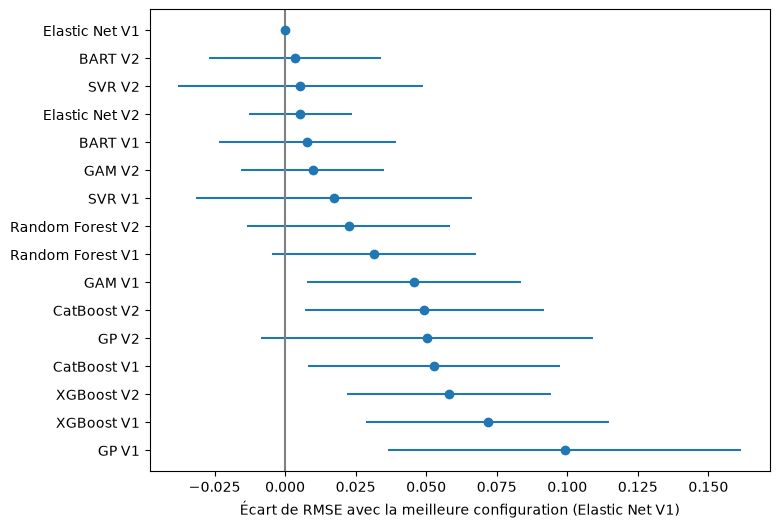

In [19]:
# Graphique : écart de RMSE de chaque configuration avec la meilleure (barres : ± une erreur standard)
plt.figure(figsize=(8, 6))
plt.errorbar(ecarts["écart"], range(len(ecarts)), xerr=ecarts["erreur standard"], fmt="o")
plt.yticks(range(len(ecarts)), ecarts.index); plt.axvline(0, c="grey"); plt.gca().invert_yaxis()
plt.xlabel(f"Écart de RMSE avec la meilleure configuration ({meilleure})")
plt.show()

In [20]:
# Niveau de simplicité de chaque modèle (ordre validé), puis configuration retenue par la règle
niveau = {"Elastic Net": 0, "GAM": 1, "SVR": 2, "GP": 3, "Random Forest": 4, "XGBoost": 5, "CatBoost": 5, "BART": 5}
choix = min(ecarts.index[ecarts["équivalente"]], key=lambda c: (niveau[c.rsplit(" ", 1)[0]], c.endswith("V1"), tableau.loc[c, "RMSE"]))
print("Configuration retenue :", choix)

Configuration retenue : Elastic Net V2


In [21]:
# La configuration retenue face aux références : écarts appariés
pd.DataFrame({f"{choix} − {r}": comparer(resultats[choix][0], references[r][0]) for r in ["Hacopian réentraîné", "moyenne", ref]}).T.round(3)

,écart,erreur standard,plis où a fait mieux (%)
Elastic Net V2 − Hacopian réentraîné,-0.007,0.062,58.0
Elastic Net V2 − moyenne,-0.024,0.059,66.0
Elastic Net V2 − Q10 = 2.0,-0.127,0.056,92.0


**Constat :**
- **10 configurations sont équivalentes à la meilleure** (écart sous une erreur standard) : Elastic Net V1 et V2, BART V1 et V2, SVR V1 et V2, GAM V2, Random Forest V1 et V2, GP V2. Notre protocole ne permet pas de les départager.
- **La règle retient la plus simple : Elastic Net V2**, une régression linéaire régularisée sur les variables choisies par le LASSO.
- **Face aux références**, Elastic Net V2 :
  - fait mieux que Q10 = 2.0 de 0.127 ± 0.056 (plus de deux erreurs standard ; mieux dans 92 % des plis) ;
  - ne se distingue ni de la moyenne (−0.024 ± 0.059) ni de Hacopian réentraîné (−0.007 ± 0.062).
- Le gain sur 2.0 dans des régions nouvelles est donc **net (≈ 12 %)**, mais il tient surtout au niveau moyen de Q10 : les variables n'apportent qu'environ 2.5 points de plus que la moyenne, un écart que notre protocole ne peut pas distinguer du hasard.

### Étape 4 — La sélection LASSO en amont aide-t-elle chaque modèle ?

**Raisonnement :** c'est la question de départ (sélection commune ou non) : pour chaque modèle, on compare V2 à V1 sur les mêmes plis. Un écart négatif signifie que la sélection aide.

In [22]:
# Écart apparié V2 − V1 pour chaque modèle
pd.DataFrame({nom: comparer(resultats[f"{nom} V2"][0], resultats[f"{nom} V1"][0]) for nom in fabriques}).T.round(3)

,écart,erreur standard,plis où a fait mieux (%)
Elastic Net,0.005,0.018,48.0
GAM,-0.036,0.033,72.0
SVR,-0.012,0.043,60.0
GP,-0.049,0.062,61.0
Random Forest,-0.009,0.019,65.0
XGBoost,-0.014,0.027,60.0
CatBoost,-0.004,0.029,53.0
BART,-0.004,0.017,58.0


**Constat :**
- La sélection LASSO en amont **aide ou est neutre pour tous les modèles**, sauf l'Elastic Net (+0.005), qui sélectionne déjà ses variables lui-même.
- Le gain est net pour le **GAM** (−0.036, au-delà d'une erreur standard, mieux dans 72 % des plis), important mais incertain pour le **GP** (−0.049 ± 0.062), et faible pour les autres (−0.004 à −0.014).
- Réponse à la question de départ : la sélection linéaire en amont **n'a pas désavantagé les modèles non linéaires**. Au contraire, avec 131 sites, réduire le nombre de variables les aide, surtout ceux qui sont les plus sensibles aux variables inutiles (GAM, GP).

## Résumé de la partie B

- **Configuration retenue par la règle : Elastic Net V2** (RMSE 0.956, soit 11.7 % de mieux que 2.0).
- **La complexité ne paie pas avec nos données** : les modèles linéaires et additifs avec peu de variables font aussi bien ou mieux que les modèles non linéaires. Le boosting et le GP avec toutes les variables font même moins bien que la simple moyenne.
- **Gain sur 2.0 dans des régions nouvelles : ≈ 12 %**, net (plus de deux erreurs standard). Mais la moyenne seule en obtient déjà 9.5 % : le supplément apporté par les variables (≈ 2.5 points) n'est distinguable ni de la moyenne ni de Hacopian réentraîné.
- **Ce qui reste à vérifier** : le comportement en extrapolation (partie C). C'est crucial pour l'Elastic Net, qui travaille sur log(Q10) : hors du domaine des données, il prolonge une droite en log, donc une exponentielle sur Q10.

## Partie C — Comportement en extrapolation

**Objectif :** vérifier comment les meilleures configurations se comportent sur la grille mondiale, en particulier **hors du domaine de nos sites**. C'est le second critère de choix du modèle.

**Raisonnement :**
1. Mesurer quelle part des terres sort du domaine de nos sites : variable par variable, puis par combinaison de variables (aire d'applicabilité, Meyer et Pebesma, 2021).
2. Entraîner sur les 131 sites la configuration retenue (Elastic Net V2) et les meilleures des autres familles (Elastic Net V1, GAM V2, SVR V2, BART V2), ainsi que l'équation publiée de Hacopian, puis prédire Q10 sur toute la grille.
3. Comparer leurs prédictions dans et hors du domaine : valeurs extrêmes, Q10 moyen, forme de la réponse hors de la plage observée.

Les variables de la grille viennent de `06_grille_mondiale.ipynb` (mêmes sources et mêmes définitions qu'à l'entraînement ; concordance vérifiée aux sites).

In [23]:
# Grille mondiale de 0.5° (cf. 06_grille_mondiale) : variables explicatives de chaque cellule, index = ligne × 720 + colonne
grille = pd.read_csv("../data/grille_05deg.csv.gz", index_col="cellule")

In [24]:
# Candidats sur la grille, au même format que X (typologie en one-hot, mêmes colonnes dans le même ordre)
X_grille = grille[candidats].join(pd.get_dummies(grille.typologie, dtype=float)).reindex(columns=X.columns, fill_value=0.0)

In [25]:
# Fonction : carte (300 × 720) d'une série indexée par les cellules de la grille, vide ailleurs
def carte(serie):
    tableau = np.full(300 * 720, np.nan)
    tableau[serie.index] = serie.values
    return tableau.reshape(300, 720)

### Étape 1 — Part des terres hors de la plage de nos sites, variable par variable

**Raisonnement :** pour chaque variable, part de la surface des terres (pondérée par l'aire des cellules) dont la valeur sort de l'intervalle [minimum, maximum] observé sur nos 131 sites.

In [26]:
# Pour chaque variable : part de la surface des terres hors de l'intervalle observé sur nos sites (%)
dehors = pd.DataFrame({v: (grille[v] < v4[v].min()) | (grille[v] > v4[v].max()) for v in candidats})
dehors.mul(grille.aire, axis=0).sum().div(grille.aire.sum()).mul(100).round(1).sort_values(ascending=False)

MAT_public      37.9
SWC_mean        26.9
logMAP          18.3
logN515         15.7
lat              9.3
SWC_warm_rel     9.1
CN               6.9
lon              6.0
pH_public        4.4
clay             1.4
sand             0.4
dtype: float64

In [27]:
# Part de la surface des terres où au moins une variable sort de l'intervalle observé
print(f"{grille.aire[dehors.any(axis=1)].sum() / grille.aire.sum():.0%} des terres ont au moins une variable hors de la plage de nos sites")

64% des terres ont au moins une variable hors de la plage de nos sites


**Constat :**
- **MAT** sort de la plage de nos sites (−5.2 à 24.5 °C) sur **38 %** des terres : déserts chauds d'un côté, Arctique et Sibérie de l'autre. Suivent `SWC_mean` (27 %), `logMAP` (18 %) et `logN515` (16 %). Les autres variables sortent de la plage sur moins de 10 % des terres.
- **64 % des terres ont au moins une variable hors de la plage de nos sites.** Sur ces surfaces, tout modèle extrapole.

### Étape 2 — Aire d'applicabilité

**Raisonnement :** une cellule peut avoir chaque variable dans la plage observée, mais une **combinaison** jamais vue (par exemple chaud, humide et acide à la fois). L'aire d'applicabilité (Meyer et Pebesma, 2021) mesure cela :
- on travaille dans l'espace des **variables retenues par le modèle choisi** (sélection LASSO sur les 131 sites), centrées-réduites ;
- l'**indice de dissimilarité** d'une cellule est sa distance au site le plus proche, divisée par la distance moyenne entre sites ;
- le **seuil** vient des sites eux-mêmes : pour chaque site, on calcule son indice par rapport aux sites des autres zones de test (premier découpage spatial), puis on prend la moustache supérieure de ces indices (3e quartile + 1.5 × écart interquartile) ;
- une cellule dont l'indice dépasse le seuil est **hors de l'aire d'applicabilité** : le modèle y extrapole.

Simplification par rapport à la méthode d'origine : les variables ne sont pas pondérées par leur importance dans le modèle.

In [28]:
# Imports : distances entre points, et sélection LASSO du protocole
from scipy.spatial.distance import cdist, pdist
from src.protocole import lasso_spatial

In [29]:
# Variables retenues par la sélection LASSO sur les 131 sites (celles qu'utilise la configuration retenue, Elastic Net V2)
retenues = list(X.columns[lasso_spatial(X, v4.log_Q10, v4.bloc)[-1].coef_ != 0])
retenues

['lat', 'lon', 'MAT_public', 'logN515', 'SWC_warm_rel', 'végétation ouverte']

In [30]:
# Sites et cellules dans l'espace des variables retenues, centré-réduit avec les moyennes et écarts-types des sites
moyenne, ecart_type = X[retenues].mean(), X[retenues].std()
Z_sites, Z_grille = ((X[retenues] - moyenne) / ecart_type).values, ((X_grille[retenues] - moyenne) / ecart_type).values

In [31]:
# Indice de dissimilarité de chaque site : distance au site le plus proche des autres zones (premier découpage), / distance moyenne entre sites
d_moyenne = pdist(Z_sites).mean()
di_sites = np.empty(len(v4))
for _, tr, te in decoupages[:5]:
    di_sites[te] = cdist(Z_sites[te], Z_sites[tr]).min(axis=1) / d_moyenne

In [32]:
# Seuil (moustache supérieure des indices des sites), puis indice de chaque cellule et appartenance à l'aire d'applicabilité
q1, q3 = np.percentile(di_sites, [25, 75])
seuil = q3 + 1.5 * (q3 - q1)
grille["applicable"] = cdist(Z_grille, Z_sites).min(axis=1) / d_moyenne <= seuil
print(f"Seuil : {seuil:.2f} | aire d'applicabilité : {grille.aire[grille.applicable].sum() / grille.aire.sum():.0%} des terres")

Seuil : 0.54 | aire d'applicabilité : 36% des terres


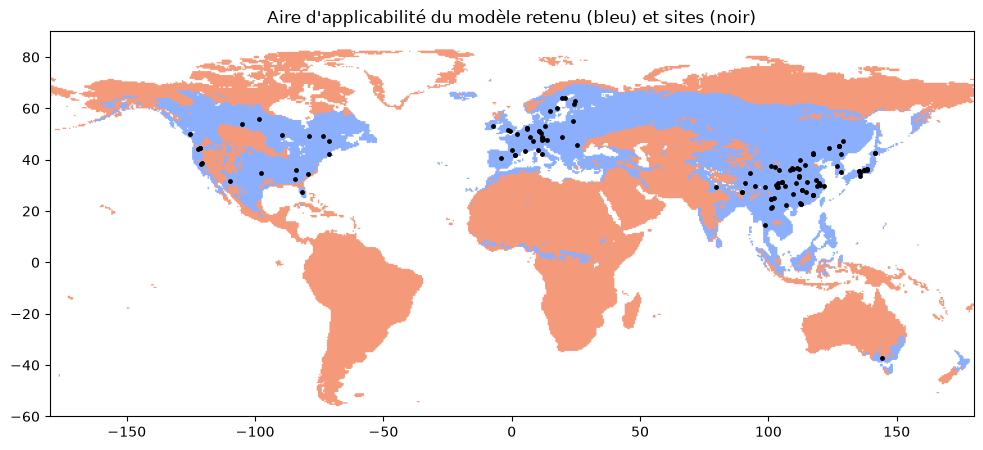

In [33]:
# Carte : aire d'applicabilité (bleu : le modèle interpole ; orange : il extrapole) et sites (points noirs)
plt.figure(figsize=(12, 5))
plt.imshow(carte(grille.applicable.astype(float)), extent=(-180, 180, -60, 90), cmap="coolwarm_r", vmin=-0.5, vmax=1.5)
plt.scatter(v4.lon, v4.lat, s=6, c="k"); plt.title("Aire d'applicabilité du modèle retenu (bleu) et sites (noir)")
plt.show()

**Constat :**
- Le modèle retenu utilise 6 variables : `lat`, `lon`, `MAT_public`, `logN515`, `SWC_warm_rel` et `végétation ouverte`.
- **L'aire d'applicabilité ne couvre que 36 % des terres** : Amérique du Nord tempérée, Europe, Chine et Asie de l'Est, nord de l'Inde, côte est de l'Australie. En sont exclues toute l'Amérique du Sud, l'Afrique, l'intérieur de l'Australie, l'Arctique et la Sibérie, l'Asie centrale et le Moyen-Orient.
- Le modèle **extrapole donc sur près des deux tiers des terres**. C'est la conséquence directe de la concentration géographique de nos sites (cf. 02, partie A).

### Étape 3 — Prédictions des modèles sur la grille

**Raisonnement :** chaque configuration est entraînée sur les 131 sites, avec la même procédure que dans la validation croisée (variante V2 : sélection LASSO d'abord), puis elle prédit Q10 sur toutes les cellules. L'équation publiée de Hacopian est appliquée telle quelle.

In [34]:
# Configurations comparées : (modèle, sélection LASSO en amont ?)
comparees = {"Elastic Net V2 (retenue)": ("Elastic Net", True), "Elastic Net V1": ("Elastic Net", False), "GAM V2": ("GAM", True), "SVR V2": ("SVR", True), "BART V2": ("BART", True)}

In [35]:
# Entraînement de chaque configuration sur les 131 sites : (modèle ajusté, variables utilisées)
ajustes = {nom: M.ajuster_final(fabriques[modele], X, v4.log_Q10, v4.bloc, selection) for nom, (modele, selection) in comparees.items()}

In [36]:
# Q10 prédit par chaque configuration sur toutes les cellules de la grille
predictions = pd.DataFrame({nom: np.exp(m.predict(X_grille[colonnes])) for nom, (m, colonnes) in ajustes.items()}, index=grille.index)

In [37]:
# Équation publiée de Hacopian, appliquée telle quelle à la grille
predictions["Hacopian publié"] = 0.1093 - 0.0315 * grille.MAT_public + 0.0002 * grille.MAP_public + 0.4112 * grille.pH_public

In [38]:
# Fonction : résumé d'une carte de Q10 (moyennes pondérées par l'aire des cellules)
def resume_carte(q):
    a, dedans = grille.aire, grille.applicable
    return pd.Series({"Q10 moyen (terres)": np.average(q, weights=a), "Q10 moyen (aire d'applicabilité)": np.average(q[dedans], weights=a[dedans]),
                      "Q10 moyen (hors aire)": np.average(q[~dedans], weights=a[~dedans]), "minimum": q.min(), "maximum": q.max(),
                      "terres hors de [0.42 ; 6.04] (%)": 100 * a[(q < v4.Q10.min()) | (q > v4.Q10.max())].sum() / a.sum()})

In [39]:
# Résumé de chaque carte ; pour mémoire, la plage observée sur nos sites va de 0.42 à 6.04
predictions.apply(resume_carte).T.round(2)

,Q10 moyen (terres),Q10 moyen (aire d'applicabilité),Q10 moyen (hors aire),minimum,maximum,terres hors de [0.42 ; 6.04] (%)
Elastic Net V2 (retenue),2.16,2.40,2.02,0.89,6.40,0.02
Elastic Net V1,2.17,2.36,2.07,1.01,5.84,0.00
GAM V2,2.06,2.38,1.87,0.72,6.46,0.02
SVR V2,2.19,2.37,2.09,1.37,3.23,0.00
BART V2,2.25,2.38,2.17,1.35,3.65,0.00
Hacopian publié,2.48,2.55,2.43,1.36,5.71,0.00


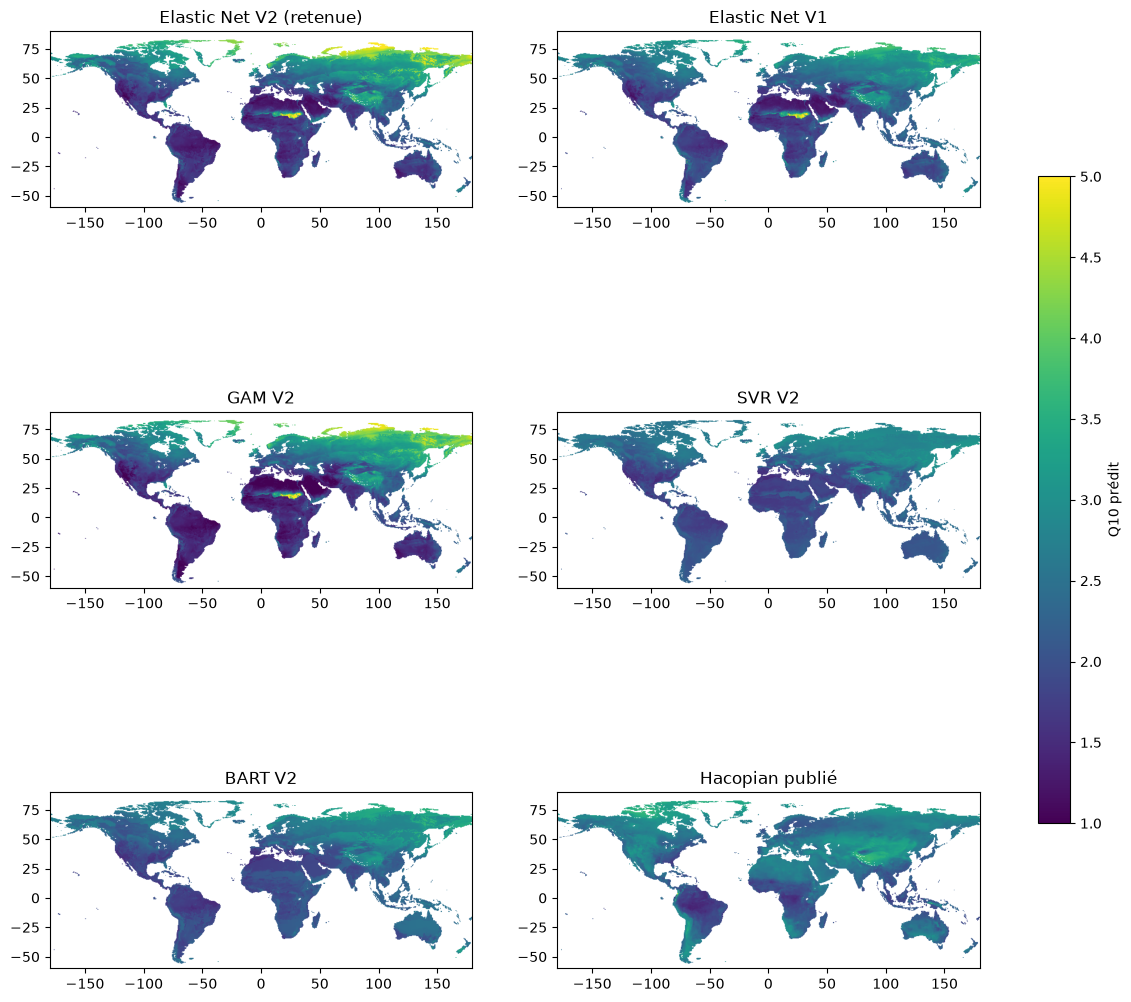

In [40]:
# Cartes de Q10 prédit (même échelle de couleurs pour toutes)
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
for ax, nom in zip(axes.flat, predictions.columns):
    im = ax.imshow(carte(predictions[nom]), extent=(-180, 180, -60, 90), vmin=1, vmax=5, cmap="viridis")
    ax.set_title(nom)
fig.colorbar(im, ax=axes, shrink=0.6, label="Q10 prédit")
plt.show()

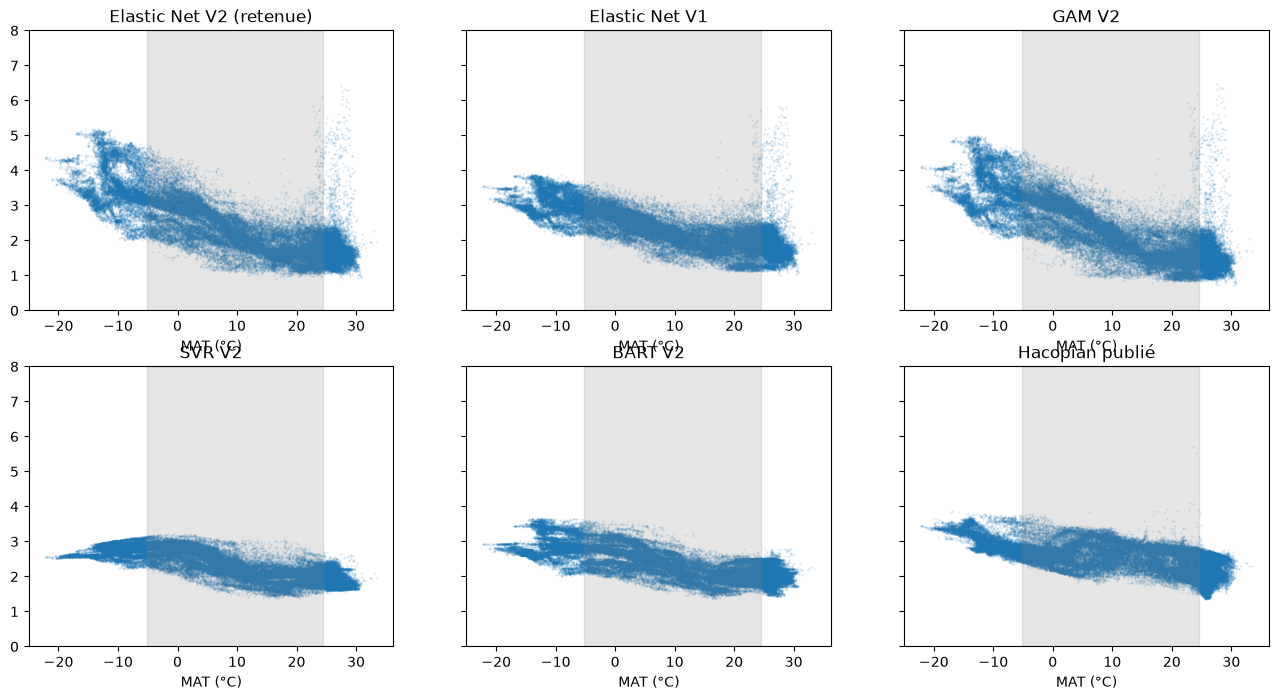

In [41]:
# Forme de la réponse : Q10 prédit en fonction de MAT (un point = une cellule) ; zone grisée = plage de MAT de nos sites
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, nom in zip(axes.flat, predictions.columns):
    ax.scatter(grille.MAT_public, predictions[nom], s=0.2, alpha=0.2)
    ax.axvspan(v4.MAT_public.min(), v4.MAT_public.max(), color="grey", alpha=0.2)
    ax.set_title(nom); ax.set_xlabel("MAT (°C)"); ax.set_ylim(0, 8)
plt.show()

**Constat :**
- **Dans l'aire d'applicabilité, les configurations s'accordent** : Q10 moyen de 2.36 à 2.40 (Hacopian publié : 2.55).
- **Hors de l'aire, elles divergent** : de 1.87 (GAM V2) à 2.17 (BART V2) en moyenne (Hacopian publié : 2.43).
- **Le Q10 moyen sur l'ensemble des terres est de 2.06 à 2.25** selon le modèle : plus bas que la moyenne de nos sites (2.51), car les régions chaudes, hors de nos données, reçoivent des Q10 bas (effet négatif de MAT).
- **Forme de la réponse** (nuages Q10–MAT) : l'Elastic Net et le GAM prolongent la tendance hors de la plage observée (Q10 plus élevé quand il fait plus froid, jusqu'à ≈ 5 en Sibérie). Le SVR et le BART s'aplatissent, comme attendu.
- **Anomalie** : l'Elastic Net et le GAM prédisent des Q10 très élevés (jusqu'à 6.4) au Sahara central, ce qui n'a pas de sens physique. Voir l'étape 4.

### Étape 4 — L'artefact saharien et le bridage des variables

**Objectif :** comprendre l'anomalie saharienne et la corriger sans changer le reste.

**Raisonnement :**
- **Cause supposée :** `SWC_warm_rel` est un rapport (humidité des mois chauds / humidité moyenne). Dans un désert hyper-aride, l'humidité d'ERA5-Land est quasi nulle : le rapport divise presque zéro par presque zéro, et devient du bruit. Comme l'Elastic Net travaille en log, il transforme ce bruit en Q10 qui explose.
- **Correction proposée : le bridage.** Avant de prédire, chaque variable est limitée à la plage [minimum ; maximum] observée sur nos sites. C'est une pratique courante pour cartographier un modèle hors de son domaine (par exemple pour les modèles de répartition d'espèces). Au-delà de la plage, la réponse devient plate pour chaque variable, comme celle des arbres.
- **Vérifications :** l'effet sur les cartes, et l'effet sur la validation croisée, en bridant à chaque pli les sites de test à la plage des sites d'entraînement.

In [42]:
# Cause : là où SWC_warm_rel dépasse 2 (au plus 1.37 sur nos sites), l'humidité moyenne est quasi nulle
grille.loc[grille.SWC_warm_rel > 2, ["SWC_warm_rel", "SWC_mean"]].describe().round(3)

,SWC_warm_rel,SWC_mean
count,358.000,358.000
mean,2.546,0.004
std,0.365,0.010
min,2.002,0.000
25%,2.235,0.001
50%,2.519,0.001
75%,2.841,0.003
max,3.297,0.075


In [43]:
# Variables de la grille bridées : chaque variable limitée à la plage [min ; max] observée sur nos sites
X_grille_bride = X_grille.clip(X.min(), X.max(), axis=1)

In [44]:
# Q10 prédit avec les variables bridées
predictions_bridees = pd.DataFrame({nom: np.exp(m.predict(X_grille_bride[colonnes])) for nom, (m, colonnes) in ajustes.items()}, index=grille.index)

In [45]:
# Fonction : Q10 moyen des terres et des régions plus froides que tous nos sites (pondéré par l'aire), et maximum au Sahara central
froid, sahara = grille.MAT_public < v4.MAT_public.min(), grille.lat.between(18, 30) & grille.lon.between(15, 35)
zones = lambda q: pd.Series({"moyen terres": np.average(q, weights=grille.aire), "moyen régions froides": np.average(q[froid], weights=grille.aire[froid]), "max Sahara": q[sahara].max(), "max": q.max()})

In [46]:
# Avant et après bridage, pour chaque configuration (Hacopian publié pour mémoire, sans bridage)
pd.concat({"sans bridage": predictions.apply(zones).T, "avec bridage": predictions_bridees.apply(zones).T}, axis=1).round(2)

sans bridage                                         \
                         moyen terres moyen régions froides max Sahara   max   
Elastic Net V2 (retenue)         2.16                  3.53       6.40  6.40   
Elastic Net V1                   2.17                  3.06       5.84  5.84   
GAM V2                           2.06                  3.45       6.46  6.46   
SVR V2                           2.19                  2.76       2.28  3.23   
BART V2                          2.25                  2.92       2.33  3.65   
Hacopian publié                  2.48                  2.97       2.89  5.71   

                         avec bridage                                         
                         moyen terres moyen régions froides max Sahara   max  
Elastic Net V2 (retenue)         2.16                  3.40       2.68  4.74  
Elastic Net V1                   2.18                  2.96       2.58  3.67  
GAM V2                           2.06                  3.33       2.47  4.61  
SVR V2                           2.20                  2.82       2.29  3.21  
BART V2                          2.25                  2.92       2.33  3.65  
Hacopian publié                   NaN                   NaN        NaN   NaN

In [47]:
# Le bridage dégrade-t-il la validation croisée ? Elastic Net V2 bridé à chaque pli, comparé à Elastic Net V2 (écart apparié)
bride = evaluer_en_cache("../resultats/04/Elastic_Net_V2_bride.pkl", lambda tr, te: M.predire_v2(fabriques["Elastic Net"], X, v4.log_Q10, v4.bloc, tr, te, brider=True), decoupages, v4.Q10)
print(f"RMSE avec bridage : {bride[0].rmse.mean():.3f}")
comparer(bride[0], resultats["Elastic Net V2"][0]).round(3)

RMSE avec bridage : 0.950


écart                       -0.006
erreur standard              0.013
plis où a fait mieux (%)    63.000
dtype: float64

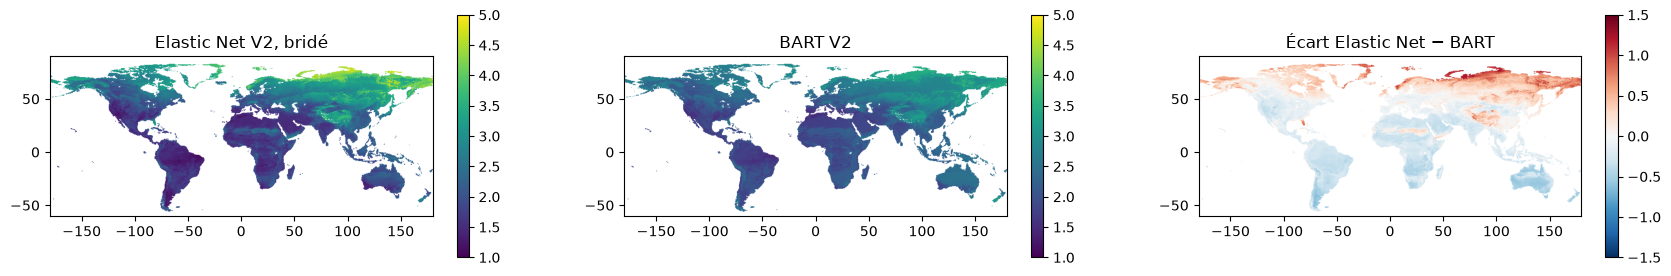

In [48]:
# Cartes : Elastic Net V2 bridé, BART V2, et leur écart (là où le choix du modèle compte)
ecart = predictions_bridees["Elastic Net V2 (retenue)"] - predictions_bridees["BART V2"]
fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
panneaux = [("Elastic Net V2, bridé", predictions_bridees["Elastic Net V2 (retenue)"], "viridis", 1, 5), ("BART V2", predictions_bridees["BART V2"], "viridis", 1, 5), ("Écart Elastic Net − BART", ecart, "RdBu_r", -1.5, 1.5)]
for ax, (titre, q, cmap, vmin, vmax) in zip(axes, panneaux):
    im = ax.imshow(carte(q), extent=(-180, 180, -60, 90), cmap=cmap, vmin=vmin, vmax=vmax); ax.set_title(titre); fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

**Constat :**
- **Cause confirmée** : les 358 cellules où `SWC_warm_rel` dépasse 2 ont une humidité moyenne quasi nulle (médiane 0.001 m³/m³). Ce sont des déserts hyper-arides, où le rapport n'a plus de sens.
- **Le bridage supprime l'artefact** : le maximum au Sahara central passe de 6.40 à 2.68 (Elastic Net V2), de 5.84 à 2.58 (Elastic Net V1) et de 6.46 à 2.47 (GAM). Le Q10 moyen des terres ne change pas (2.16 pour Elastic Net V2). Le SVR et le BART, déjà plats hors de la plage, ne changent pas.
- **Le bridage ne dégrade pas la validation croisée**, il l'améliore même légèrement : 0.950 contre 0.956 (−0.006 ± 0.013 ; mieux dans 63 % des plis).
- **Un désaccord demeure dans les régions froides** (MAT inférieure à celle de tous nos sites, soit 10 % des terres) : Q10 moyen de 3.40 (Elastic Net V2 bridé) et 3.33 (GAM), contre 2.96 (Elastic Net V1), 2.92 (BART), 2.82 (SVR) et 2.97 (Hacopian publié). La carte des écarts le montre : l'Elastic Net donne des Q10 plus élevés que le BART en Sibérie, en Arctique et au Tibet (jusqu'à +1.5), et un peu plus bas sous les tropiques (−0.3 à −0.6). Aucun de nos sites n'est aussi froid : **nos données ne permettent pas de trancher.**

## Conclusion de la partie C

- **Le modèle extrapole sur 64 % des terres** (aire d'applicabilité : 36 %). C'est la conséquence directe de la concentration de nos sites en Amérique du Nord, en Europe et en Asie de l'Est.
- **Dans l'aire d'applicabilité, tous les modèles s'accordent** (Q10 moyen ≈ 2.4). **Hors de l'aire, ils divergent**, surtout dans les régions froides, qui sont pourtant les plus importantes pour le carbone du sol (permafrost).
- **Le Q10 moyen mondial prédit est d'environ 2.1 à 2.2** selon le modèle, proche de la valeur fixe 2.0. L'apport d'une carte pour ORCHIDEE tient donc surtout à la **répartition spatiale** de Q10 (plus élevé au froid, plus bas au chaud), et beaucoup moins à son niveau moyen.
- **Second critère de choix** : l'Elastic Net V2 seul extrapole mal (artefact saharien, exponentielle en log). Avec le bridage, il reste le plus simple, l'artefact disparaît, et la validation croisée s'améliore légèrement.

**Décisions proposées (à valider par l'équipe) :**
1. Pour la carte, retenir **Elastic Net V2 avec bridage des variables**.
2. Livrer la carte **avec son aire d'applicabilité**, pour signaler où les valeurs sont des extrapolations.
3. Pour les régions froides, où le choix du modèle change le Q10 d'environ 0.5, produire aussi la carte **BART V2** comme variante de sensibilité, et demander l'avis de B. Guenet (ou s'appuyer sur la littérature des hautes latitudes) pour trancher.

## Partie D — Le coefficient de détermination R²

**Objectif :** calculer et analyser le R² de toutes les configurations. C'est la métrique la plus utilisée avec B. Guenet pour juger la qualité explicative d'un modèle.

**Raisonnement :** le R² est la part de la variance de Q10 expliquée par les prédictions :
$$R^2 = 1 - \frac{\sum_i (Q_{10,i} - \widehat{Q}_{10,i})^2}{\sum_i (Q_{10,i} - \overline{Q}_{10})^2}.$$
Il vaut 1 pour des prédictions parfaites, 0 pour un modèle qui prédit la moyenne, et devient **négatif** si le modèle fait moins bien que la moyenne. Selon **sur quels sites** on évalue les prédictions, il mesure des choses très différentes :
- **R² d'ajustement** : modèle entraîné sur les 131 sites et évalué sur ces mêmes sites. C'est le **pouvoir explicatif**, celui que rapportent les régressions des articles (Hacopian : $r$ multiple de 0.39 pour MAT + MAP + pH, soit $R^2 \approx 0.15$ sur ses données). Il est optimiste : un modèle flexible peut apprendre ses sites par cœur.
- **R² en validation croisée aléatoire** : sites de test nouveaux, mais leurs voisins restent à l'entraînement.
- **R² en validation croisée spatiale** : régions entières nouvelles. C'est le **pouvoir prédictif** qui compte pour la carte.

Repère : le bruit local entre mesures d'un même site limite le R² atteignable à ≈ 0.78 (cf. `01_EDA.ipynb`). On calcule aussi le **r²** (carré de la corrélation entre Q10 observé et prédit) en validation croisée spatiale : il mesure seulement si le modèle classe les sites dans le bon ordre, sans pénaliser un décalage ou une mauvaise échelle des prédictions.

In [49]:
# Imports : découpage aléatoire
from sklearn.model_selection import KFold

In [50]:
# Fonction : R² sur l'échelle de Q10 (part de la variance de Q10 expliquée par les prédictions p)
r2 = lambda p: 1 - ((v4.Q10.values - p) ** 2).sum() / ((v4.Q10.values - v4.Q10.mean()) ** 2).sum()

In [51]:
# Les 16 configurations : (modèle, sélection LASSO en amont ?)
configurations = {f"{nom} {v}": (nom, v == "V2") for nom in fabriques for v in ["V1", "V2"]}

In [52]:
# R² d'ajustement : chaque configuration est entraînée sur les 131 sites, puis évaluée sur ces mêmes sites
r2_ajustement = {}
for config, (nom, selection) in configurations.items():
    X_config = X_cat if (nom == "CatBoost" and not selection) else X
    m, colonnes = M.ajuster_final(fabriques[nom], X_config, v4.log_Q10, v4.bloc, selection)
    r2_ajustement[config] = r2(np.exp(m.predict(X_config[colonnes])))

In [53]:
# R² en validation croisée spatiale : R² des prédictions hors échantillon de chaque répétition (partie B), moyenné sur les 20 répétitions
r2_spatial = {config: np.mean([r2(o) for o in resultats[config][1]]) for config in configurations}

In [54]:
# r² en validation croisée spatiale : carré de la corrélation entre Q10 observé et prédit, moyenné sur les 20 répétitions
r2_correlation = {config: np.mean([np.corrcoef(v4.Q10, o)[0, 1] ** 2 for o in resultats[config][1]]) for config in configurations}

In [55]:
# Découpages aléatoires (5 plis × 5 répétitions), qui ignorent la géographie
decoupages_aleatoires = [(s, tr, te) for s in range(5) for tr, te in KFold(5, shuffle=True, random_state=s).split(v4)]

In [56]:
# R² en validation croisée aléatoire (≈ 10 min au premier calcul, puis lecture du cache dans resultats/04/aleatoire/)
r2_aleatoire = {}
for config, (nom, selection) in configurations.items():
    X_config = X_cat if (nom == "CatBoost" and not selection) else X
    predire = M.predire_v2 if selection else M.predire_v1
    _, oof = evaluer_en_cache(f"../resultats/04/aleatoire/{config.replace(' ', '_')}.pkl", lambda tr, te: predire(fabriques[nom], X_config, v4.log_Q10, v4.bloc, tr, te), decoupages_aleatoires, v4.Q10)
    r2_aleatoire[config] = np.mean([r2(o) for o in oof])

In [57]:
# Références : prédicteurs pour les validations croisées, et prédictions d'ajustement sur les 131 sites
predicteurs_refs = {ref: lambda tr, te: np.full(len(te), Q10_REFERENCE), "moyenne": lambda tr, te: np.full(len(te), v4.Q10.iloc[tr].mean()),
                    "Hacopian réentraîné": lambda tr, te: LinearRegression().fit(H.iloc[tr], v4.Q10.iloc[tr]).predict(H.iloc[te]), "Hacopian publié": lambda tr, te: hacopian_publie.iloc[te]}
ajustement_refs = {ref: np.full(len(v4), Q10_REFERENCE), "moyenne": np.full(len(v4), v4.Q10.mean()),
                   "Hacopian réentraîné": LinearRegression().fit(H, v4.Q10).predict(H), "Hacopian publié": hacopian_publie.values}

In [58]:
# Les trois R² des références
for nom in predicteurs_refs:
    r2_ajustement[nom] = r2(ajustement_refs[nom])
    r2_spatial[nom] = np.mean([r2(o) for o in references[nom][1]])
    r2_aleatoire[nom] = np.mean([r2(o) for o in evaluer(predicteurs_refs[nom], decoupages_aleatoires, v4.Q10)[1]])

In [59]:
# Tableau : R² d'ajustement, en validation croisée aléatoire et spatiale, et r² en validation croisée spatiale (trié par R² d'ajustement)
tableau_r2 = pd.DataFrame({"R² ajustement": r2_ajustement, "R² VC aléatoire": r2_aleatoire, "R² VC spatiale": r2_spatial, "r² VC spatiale": r2_correlation}).sort_values("R² ajustement", ascending=False)
tableau_r2.round(3)

,R² ajustement,R² VC aléatoire,R² VC spatiale,r² VC spatiale
GP V1,0.882,-0.047,-0.187,0.007
CatBoost V1,0.624,0.004,-0.098,0.025
CatBoost V2,0.571,0.002,-0.087,0.031
XGBoost V1,0.570,-0.026,-0.148,0.014
XGBoost V2,0.494,0.012,-0.104,0.026
Random Forest V1,0.477,0.045,-0.052,0.029
Random Forest V2,0.424,0.059,-0.030,0.044
GP V2,0.302,-0.022,-0.081,0.043
BART V1,0.254,0.071,-0.001,0.043
SVR V1,0.230,0.080,-0.012,0.056


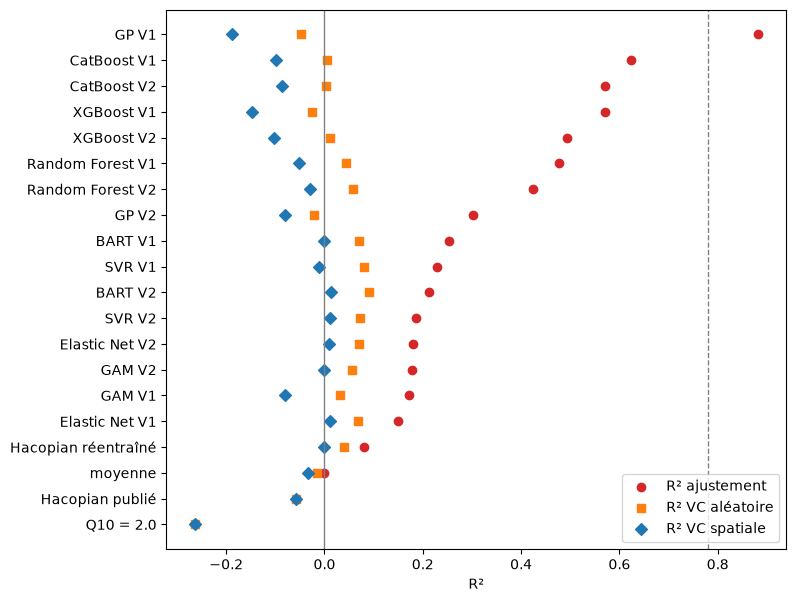

In [60]:
# Graphique : les trois R² de chaque configuration et référence ; pointillés : plafond ≈ 0.78 (bruit local)
fig, ax = plt.subplots(figsize=(8, 7))
for colonne, couleur, marque in [("R² ajustement", "C3", "o"), ("R² VC aléatoire", "C1", "s"), ("R² VC spatiale", "C0", "D")]:
    ax.scatter(tableau_r2[colonne], range(len(tableau_r2)), color=couleur, marker=marque, label=colonne)
ax.axvline(0, c="grey", lw=1); ax.axvline(0.78, c="grey", ls="--", lw=1)
ax.set_yticks(range(len(tableau_r2)), tableau_r2.index); ax.invert_yaxis(); ax.set_xlabel("R²"); ax.legend(loc="lower right")
plt.show()

**Constat :**
- **R² d'ajustement : l'ordre est inversé.** Les modèles les plus flexibles « expliquent » le mieux leurs propres sites : GP V1 0.88, CatBoost 0.57 à 0.62, XGBoost 0.49 à 0.57, forêt aléatoire 0.42 à 0.48. Ce sont pourtant eux qui prédisent le moins bien les régions nouvelles (R² spatial de −0.19 à −0.03). Le GP V1 dépasse même le plafond de ≈ 0.78 fixé par le bruit local : il apprend ce bruit par cœur.
- **Les modèles retenus ont un pouvoir explicatif modeste** : R² d'ajustement de 0.15 à 0.21 (Elastic Net, GAM, SVR V2, BART V2). C'est dans l'ordre de grandeur de Hacopian (≈ 0.15 sur ses données ; 0.08 pour sa forme de modèle sur nos sites).
- **Même en validation croisée aléatoire**, où les voisins des sites de test sont connus, le R² ne dépasse pas 0.09 (BART V2 ; Elastic Net ≈ 0.07). Les modèles flexibles y sont déjà négatifs ou quasi nuls.
- **En validation croisée spatiale**, le R² vaut au mieux 0.013. Le r² atteint 0.07 à 0.08 (Elastic Net V2, GAM V2) : les modèles classent un peu les sites dans le bon ordre, mais leurs prédictions sont trop resserrées autour de la moyenne pour réduire beaucoup l'erreur.
- **Lecture pour la carte** : le pouvoir explicatif d'ajustement (≈ 0.15–0.2) surestime nettement ce que le modèle apporte dans des régions sans mesure (≈ 0.01). C'est le R² spatial qu'il faut retenir pour juger la carte.